In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import warnings
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")


data = {
 "Exercise_Time(min)": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55,
 60, 65, 70, 75, 80, 85, 90, 95, 100, 105,
 110, 115, 120],
 "Calories_Burned": [50, 80, 100, 130, 160, 190, 210, 240, 270,
290,
 320, 350, 370, 400, 430, 460, 490, 520, 540,
570,
 600, 630, 650]
}


   Exercise_Time(min)  Calories_Burned
0                  10               50
1                  15               80
2                  20              100
3                  25              130
4                  30              160
Equation of the line: y = 5.49x + -6.99
Predicted Calories burned:157.78


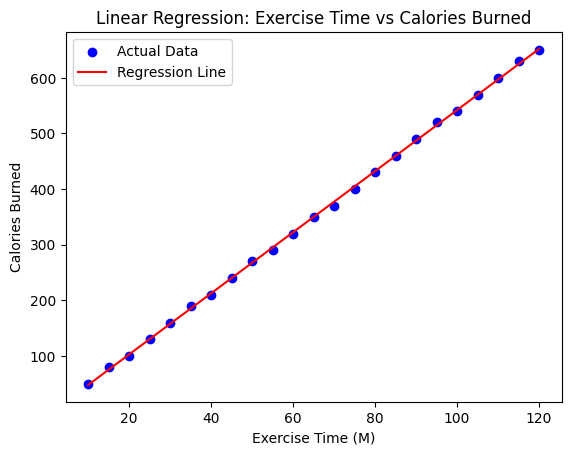

In [2]:
df = pd.DataFrame(data)
print(df.head())
model = LinearRegression()

X = df[['Exercise_Time(min)']]
y = df['Calories_Burned']
model.fit(X, y)
LinearRegression()

slope = model.coef_[0]
intercept = model.intercept_
print(f"Equation of the line: y = {slope:.2f}x + {intercept:.2f}")

predicted_score = model.predict([[30]])
print(f"Predicted Calories burned:{predicted_score[0]:.2f}")

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, model.predict(X), color="red", label="Regression Line")
plt.xlabel("Exercise Time (M)")
plt.ylabel("Calories Burned")
plt.title("Linear Regression: Exercise Time vs Calories Burned")
plt.legend()
plt.show()

In [3]:
data = {
    "Engine_Size(L)": [
        1.0, 1.2, 1.4, 1.6, 1.8,
        2.0, 2.2, 2.5, 3.0, 3.5,
        4.0, 4.5, 5.0, 5.5, 6.0
    ],
    "CO2_Emissions(g/km)": [
        95, 105, 118, 135, 150,
        170, 190, 220, 270, 320,
        380, 440, 510, 590, 680
    ]
}


In [4]:
df = pd.DataFrame(data)

X = df[["Engine_Size(L)"]]
y = df["CO2_Emissions(g/km)"]

In [5]:
# Train model
model = LinearRegression()
model.fit(X, y)

# Custom input (Engine Size)
engine_size = 3.2
predicted_emission = model.predict([[engine_size]])

# Output
print(f"\nPredicted CO₂ Emissions at {engine_size}L engine size: {predicted_emission[0]:.2f} g/km")


Predicted CO₂ Emissions at 3.2L engine size: 312.79 g/km


In [6]:
# Predict emissions for given engine sizes
engine_1 = 2.5
predicted_1 = model.predict([[engine_1]])
print(f"\nPredicted CO₂ Emissions at {engine_1}L engine: {predicted_1[0]:.2f} g/km")

engine_2 = 4.0
predicted_2 = model.predict([[engine_2]])
print(f"Predicted CO₂ Emissions at {engine_2}L engine: {predicted_2[0]:.2f} g/km")


Predicted CO₂ Emissions at 2.5L engine: 233.09 g/km
Predicted CO₂ Emissions at 4.0L engine: 403.87 g/km


In [7]:
custom_engine = 5.0  # engine size in liters
predicted_custom = model.predict([[custom_engine]])
print(f"\nPredicted CO₂ Emissions at {custom_engine}L engine: {predicted_custom[0]:.2f} g/km")



Predicted CO₂ Emissions at 5.0L engine: 517.72 g/km


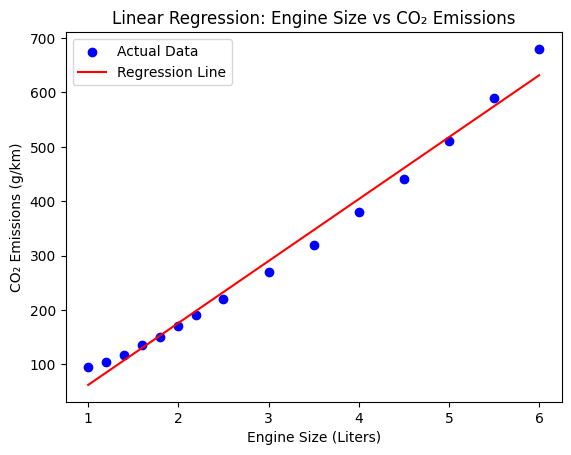

In [8]:

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, model.predict(X), color="red", label="Regression Line")
plt.xlabel("Engine Size (Liters)")
plt.ylabel("CO₂ Emissions (g/km)")
plt.title("Linear Regression: Engine Size vs CO₂ Emissions")
plt.legend()
plt.show()


In [9]:
# Predictions
y_pred = model.predict(X)

# Calculate evaluation metrics
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

# Print the metrics
print("Model Evaluation Metrics (Engine Size vs CO₂ Emissions):")
print(f"  Mean Absolute Error (MAE): {mae:.2f}")
print(f"  Mean Squared Error (MSE): {mse:.2f}")
print(f"  R-squared (R²): {r2:.2f}")

Model Evaluation Metrics (Engine Size vs CO₂ Emissions):
  Mean Absolute Error (MAE): 17.46
  Mean Squared Error (MSE): 443.81
  R-squared (R²): 0.99


Polynomial Regression Performance:
  Mean Absolute Error (MAE): 2.50
  Mean Squared Error (MSE): 8.37
  R-squared (R²): 1.00


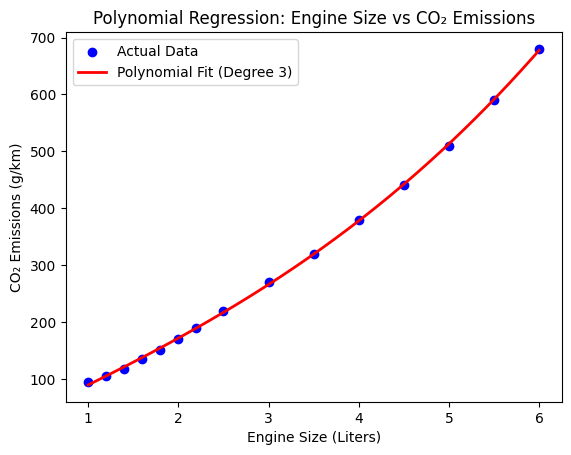

In [10]:
# Polynomial transformation (degree 3)
poly = PolynomialFeatures(degree=3)
X_poly = poly.fit_transform(X)

# Train model
model = LinearRegression()
model.fit(X_poly, y)

# Predict values
y_pred = model.predict(X_poly)

# Evaluation
mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("Polynomial Regression Performance:")
print(f"  Mean Absolute Error (MAE): {mae:.2f}")
print(f"  Mean Squared Error (MSE): {mse:.2f}")
print(f"  R-squared (R²): {r2:.2f}")

# Visualization
X_range = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
X_range_poly = poly.transform(X_range)
y_range_pred = model.predict(X_range_poly)

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X_range, y_range_pred, color="red", linewidth=2, label="Polynomial Fit (Degree 3)")
plt.xlabel("Engine Size (Liters)")
plt.ylabel("CO₂ Emissions (g/km)")
plt.title("Polynomial Regression: Engine Size vs CO₂ Emissions")
plt.legend()
plt.show()

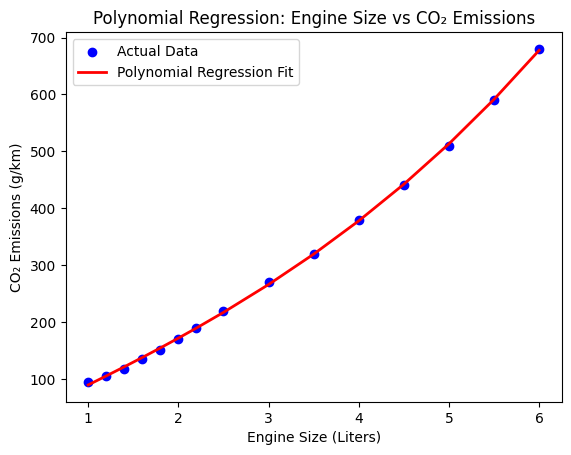

In [11]:
# Sort values for smooth curve
X_sorted = np.sort(X.values.flatten())
X_sorted_poly = poly.transform(X_sorted.reshape(-1, 1))
y_pred_sorted = model.predict(X_sorted_poly)

# Plot
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X_sorted, y_pred_sorted, color='red', linewidth=2, label='Polynomial Regression Fit')
plt.xlabel("Engine Size (Liters)")
plt.ylabel("CO₂ Emissions (g/km)")
plt.title("Polynomial Regression: Engine Size vs CO₂ Emissions")
plt.legend()
plt.show()


How did creating your own datasets and building a linear model deepen your understanding of how regression equations represent real-world relationships?

• I understood better how to use regression to show the relationship between variables. For example, in engine size and emission, as engine size increases, emissions also increase.

In what ways did Python programming (coding, visualization, and analysis) help you interpret the slope and intercept of your model?

• Python was a big help because it made it easier to see the slope and intercept using visualization—whether the line is going upward or downward, and how fast the values are changing.

Which of the datasets or topics you worked on produced the most accurate predictions, and what factors might have influenced that accuracy?

• The most accurate dataset was the one with a linear relationship, such as Exercise Time vs. Calories Burned, because the x and y values were highly correlated.

What limitations or potential sources of error did you observe when applying linear regression to your chosen topics?

• A limitation of linear regression is when the relationship is not linear. In my dataset, some values were non-collinear.

How can the concepts and skills you practiced (data generation, model building, and interpretation) be applied to decision-making in fields such as education, business, or health?

• These can be applied in different fields. For example, in business to see the effect of price on demand, and in health to model exercise time and calories burned. This helps in making data-driven decisions.

If you were to improve your model or dataset, what changes would you make to enhance its reliability and usefulness?

• I would add a larger dataset with more realistic values and use polynomial regression to make the predictions more accurate.

Reflect on the coding challenges you faced during this activity—what specific skills or strategies helped you overcome them?

• I had difficulty predicting engine size and emission because they didn’t fit directly into a linear model. But I learned to use polynomial regression, which was a better fit for the dataset.